# 02 – Four churn prediction models

Predicts customer churn from `clean_train.csv` (built in notebook 01) with 4 models: **KNN**, **Random Forest**, **Gradient Boosting**, **XGBoost**. It then tunes Gradient Boosting, extracts decision-tree rules and summarises the results.

Setup:
- The 5 categorical variables are encoded with `LabelEncoder`
- 70% train / 30% test split, `random_state=4`
- Every model has a fixed `random_state` so results are reproducible

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

import sklearn, xgboost
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, roc_curve, recall_score,
                             precision_score, f1_score, ConfusionMatrixDisplay)

warnings.filterwarnings('ignore')
RESULTS = Path('results'); RESULTS.mkdir(exist_ok=True)
print('sklearn', sklearn.__version__, '| xgboost', xgboost.__version__)

sklearn 1.7.2 | xgboost 3.2.0


## 1. Load data & rename columns

In [2]:
cust = pd.read_csv('clean_train.csv')
cust = cust.rename(columns={
    'customer_number': 'Customer_number', 'client_sex': 'Client_gender', 'staff_vib': 'Staff_VIB',
    'sms': 'SMS', 'No.Activity_Name': 'No_Activity_Name', 'Type_Trans_LV2': 'Type_Transaction',
    'Avg_trans_no/month': 'Avg_trans_no_month',
})
# Drop customer ID, registration date (captured by Tenure) and max_datediff (used to build the label -> leakage)
training_data = cust.drop(columns=['Customer_number', 'IB_REGISTER_DATE', 'max_datediff'])
print(training_data.shape)
training_data.head()

(66763, 29)


,Client_gender,Age,Staff_VIB,SMS,Verify_method,Tenure,EB_register_channel,No_Activity_Name,Type_Transaction,Total_trans_no,...,Avg_TermDeposite_Balance,max_TermDeposite_Balance,min_TermDeposite_Balance,No_Loan,Avg_Loan_Balance,max_Loan_Balance,min_Loan_Balance,No_CC,No_DC,churn
0,M,23,N,Y,SMART_OTP,1.73,BRANCH,10,3,38,...,0.000000e+00,0.000000e+00,0.0,0,0,0,0,0,1,0
1,F,42,N,Y,SMS,9.60,BRANCH,10,4,52,...,0.000000e+00,0.000000e+00,0.0,0,0,0,0,0,1,0
2,M,25,N,Y,SMART_OTP,4.67,BRANCH,13,1,2,...,0.000000e+00,0.000000e+00,0.0,0,0,0,0,0,1,0
3,F,22,N,N,SMS,10.73,BRANCH,10,1,2,...,3.463551e+08,1.270000e+09,0.0,0,0,0,0,0,0,0
4,M,33,N,Y,SMART_OTP,8.60,BRANCH,14,4,95,...,0.000000e+00,0.000000e+00,0.0,0,0,0,0,0,2,1


## 2. Encode categorical variables

In [3]:
target_col = 'churn'
cat_cols = [c for c in training_data.columns if training_data[c].nunique() < 6 and c != target_col]
print('Categorical:', cat_cols)
print('Missing values:', int(training_data.isnull().sum().sum()))

for col in cat_cols:
    training_data[col] = LabelEncoder().fit_transform(training_data[col])

Categorical: ['Client_gender', 'Staff_VIB', 'SMS', 'Verify_method', 'EB_register_channel']
Missing values: 0


## 3. Train / test split (70/30)

In [4]:
X = training_data.drop(columns=target_col)
y = training_data[target_col]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=4)

table2 = pd.DataFrame({
    'Non-churner': [ (y_test == 0).sum(), (y_train == 0).sum(), (y == 0).sum()],
    'Churner':     [ (y_test == 1).sum(), (y_train == 1).sum(), (y == 1).sum()],
}, index=['y_test', 'y_train', 'Total'])
table2['% Churn rate'] = (table2['Churner'] / (table2['Churner'] + table2['Non-churner'])).map('{:.0%}'.format)
table2

,Non-churner,Churner,% Churn rate
y_test,12908,7121,36%
y_train,30095,16639,36%
Total,43003,23760,36%


## 4. Train the 4 models

In [5]:
models = {
    'KNN': KNeighborsClassifier(n_neighbors=5, weights='uniform', algorithm='auto', leaf_size=30,
                                p=2, metric='minkowski'),
    'Random Forest': RandomForestClassifier(n_estimators=10, criterion='gini', random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(loss='log_loss', n_estimators=200, random_state=42),
    'XGBoost': XGBClassifier(learning_rate=0.1, n_estimators=177, max_depth=4, min_child_weight=6,
                             gamma=0.1, subsample=0.8, colsample_bytree=0.8, objective='binary:logistic',
                             n_jobs=4, scale_pos_weight=1, random_state=27),
}
for name, m in models.items():
    m.fit(X_train, y_train)
    print('trained', name)

trained KNN


trained Random Forest


trained Gradient Boosting


trained XGBoost


## 5. Evaluation

In [6]:
rows, probas = {}, {}
for name, m in models.items():
    proba = m.predict_proba(X_test)[:, 1]
    pred = m.predict(X_test)
    probas[name] = proba
    rows[name] = {
        'Accuracy': accuracy_score(y_test, pred),
        'Roc_Auc': roc_auc_score(y_test, proba),
        'F1_Score': f1_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
    }
df_metrics = pd.DataFrame(rows).T
df_metrics.to_csv(RESULTS / 'metrics.csv')
df_metrics.style.format('{:.2%}')

,Accuracy,Roc_Auc,F1_Score,Recall,Precision
KNN,61.84%,58.84%,38.71%,33.90%,45.12%
Random Forest,76.99%,82.41%,64.79%,59.53%,71.06%
Gradient Boosting,79.46%,86.13%,69.45%,65.66%,73.70%
XGBoost,79.58%,86.25%,69.84%,66.51%,73.53%


## 6. Confusion matrices

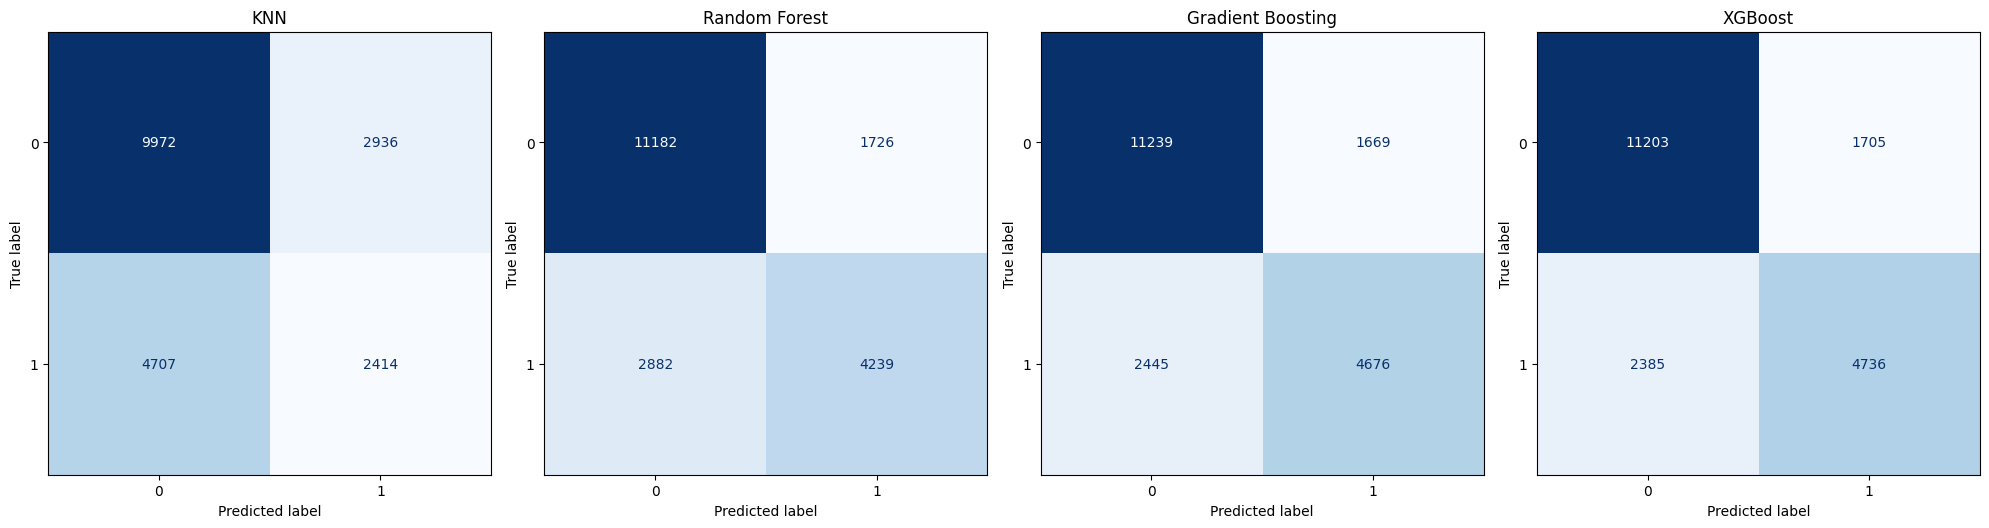

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (name, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, cmap=plt.cm.Blues, values_format='.0f',
                                          ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig(RESULTS / 'confusion_matrices.png', dpi=150)
plt.show()

## 7. ROC curves

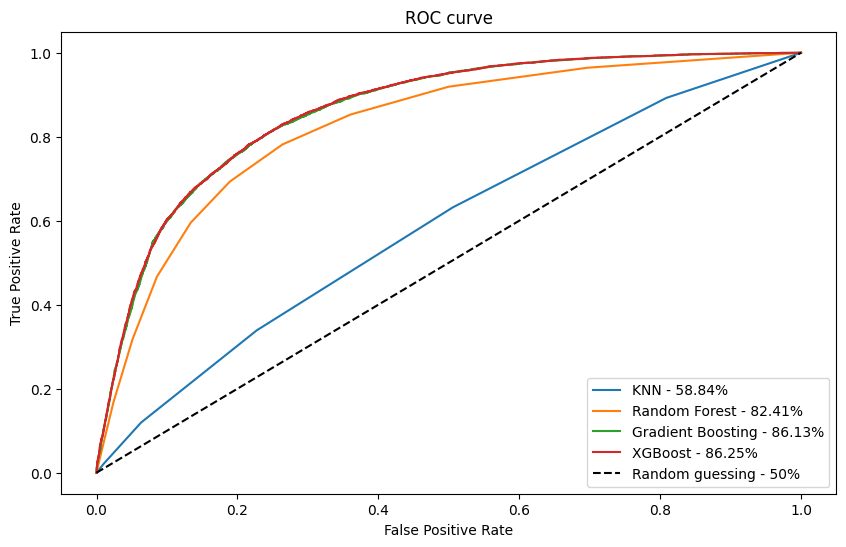

In [8]:
plt.figure(figsize=(10, 6))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f'{name} - {rows[name]["Roc_Auc"]:.2%}')
plt.plot([0, 1], [0, 1], 'k--', label='Random guessing - 50%')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.title('ROC curve')
plt.legend(loc='lower right')
plt.savefig(RESULTS / 'roc_curves.png', dpi=150)
plt.show()

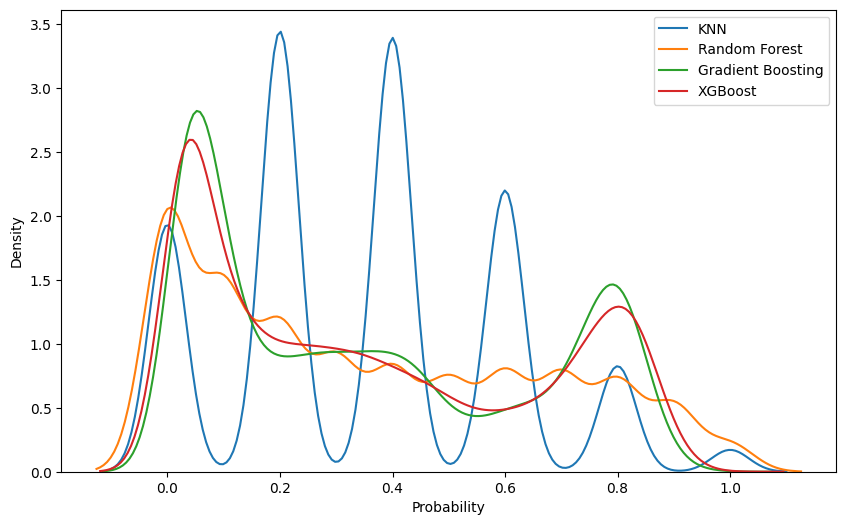

In [9]:
plt.figure(figsize=(10, 6))
for name, proba in probas.items():
    sns.kdeplot(proba, label=name)
plt.xlabel('Probability'); plt.ylabel('Density'); plt.legend()
plt.savefig(RESULTS / 'probability_density.png', dpi=150)
plt.show()

## 8. Feature importance (XGBoost)

Importance is measured with XGBoost's `weight` type: the number of times a feature is used to split.

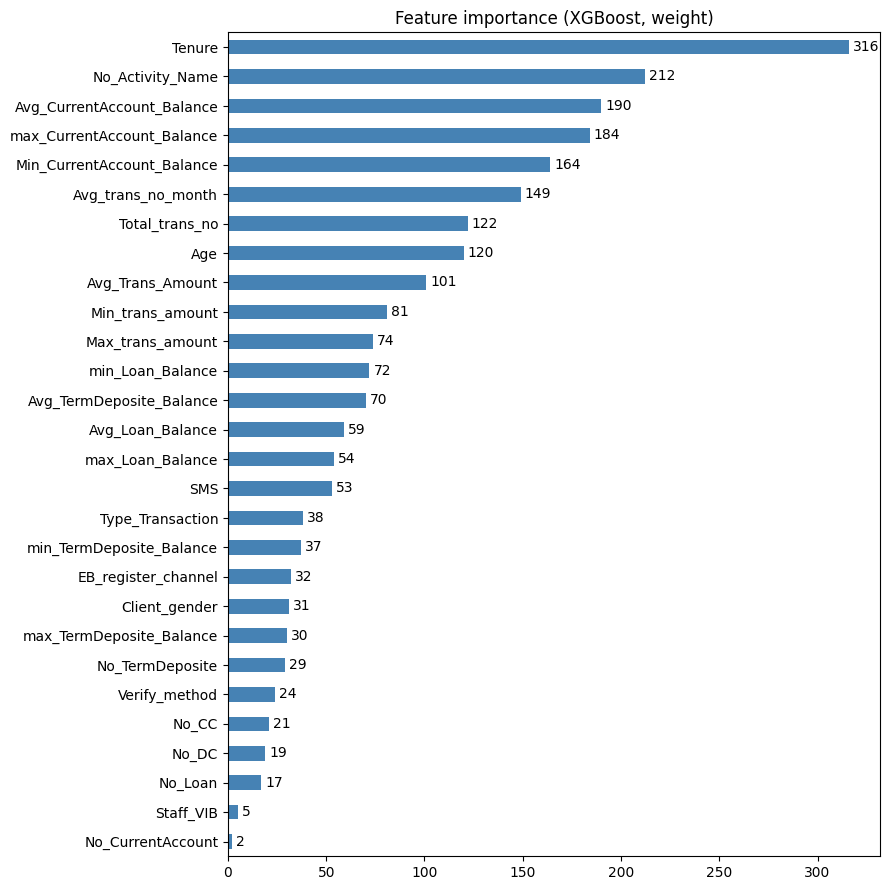

In [10]:
imp = pd.Series(models['XGBoost'].get_booster().get_score(importance_type='weight')).sort_values()
imp.to_csv(RESULTS / 'feature_importance.csv', header=['weight'])
ax = imp.plot.barh(figsize=(9, 9), color='steelblue')
for i, v in enumerate(imp):
    ax.text(v + 2, i, str(int(v)), va='center')
plt.title('Feature importance (XGBoost, weight)')
plt.tight_layout()
plt.savefig(RESULTS / 'feature_importance.png', dpi=150)
plt.show()

## 9. Tuned Gradient Boosting

Gradient Boosting with tuned hyperparameters from a grid search: `learning_rate=0.1, min_samples_split=500, min_samples_leaf=50, max_depth=8, max_features='sqrt', subsample=0.8, random_state=10`.

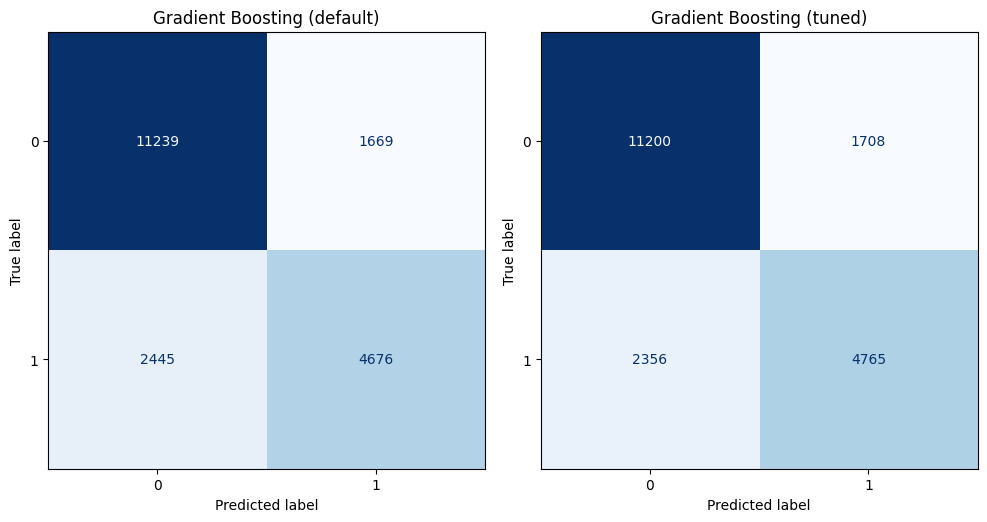

,Accuracy,Roc_Auc,F1_Score,Recall,Precision
Gradient Boosting,79.46%,86.13%,69.45%,65.66%,73.70%
Gradient Boosting (tuned),79.71%,86.23%,70.10%,66.91%,73.61%


In [11]:
def evaluate(model):
    proba = model.predict_proba(X_test)[:, 1]
    pred = model.predict(X_test)
    return {
        'Accuracy': accuracy_score(y_test, pred),
        'Roc_Auc': roc_auc_score(y_test, proba),
        'F1_Score': f1_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
    }

gb_tuned = GradientBoostingClassifier(learning_rate=0.1, min_samples_split=500, min_samples_leaf=50,
                                      max_depth=8, max_features='sqrt', subsample=0.8, random_state=10)
gb_tuned.fit(X_train, y_train)
rows['Gradient Boosting (tuned)'] = evaluate(gb_tuned)
probas['Gradient Boosting (tuned)'] = gb_tuned.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (name, m) in zip(axes, [('Gradient Boosting (default)', models['Gradient Boosting']),
                                 ('Gradient Boosting (tuned)', gb_tuned)]):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, cmap=plt.cm.Blues, values_format='.0f',
                                          ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig(RESULTS / 'gb_tuned_confusion_matrix.png', dpi=150)
plt.show()

pd.DataFrame(rows).T.loc[['Gradient Boosting', 'Gradient Boosting (tuned)']].style.format('{:.2%}')

## 10. Decision-tree classification rules

A depth-5 decision tree (`max_depth=5, random_state=1234`) gives readable "If–Then" rules for classifying churners and non-churners.

In [12]:
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree, _tree

dt = DecisionTreeClassifier(max_depth=5, random_state=1234)
dt.fit(X_train, y_train)
rows['Decision Tree (depth 5)'] = evaluate(dt)
pd.DataFrame(rows).T.loc[['Decision Tree (depth 5)']].style.format('{:.2%}')

,Accuracy,Roc_Auc,F1_Score,Recall,Precision
Decision Tree (depth 5),79.20%,84.98%,69.20%,65.75%,73.04%


In [13]:
def get_rules(tree, feature_names, class_names):
    # Turn every root-to-leaf path into an If-Then rule, sorted by number of training samples
    t = tree.tree_
    names = [feature_names[i] if i != _tree.TREE_UNDEFINED else None for i in t.feature]
    paths = []

    def recurse(node, conds):
        if t.feature[node] != _tree.TREE_UNDEFINED:
            thr = np.round(t.threshold[node], 3)
            recurse(t.children_left[node], conds + [f'({names[node]} <= {thr})'])
            recurse(t.children_right[node], conds + [f'({names[node]} > {thr})'])
        else:
            paths.append((conds, t.value[node][0], t.n_node_samples[node]))

    recurse(0, [])
    paths.sort(key=lambda p: p[2], reverse=True)
    rules = []
    for conds, value, n in paths:
        k = int(np.argmax(value))
        rules.append({
            'Rule': ' and '.join(conds),
            'Result': class_names[k],
            'Probability': value[k] / value.sum(),
            'Samples': n,
        })
    return pd.DataFrame(rules)

rules = get_rules(dt, X.columns.tolist(), ['Non-churner', 'Churner'])
rules.index = rules.index + 1
rules.to_csv(RESULTS / 'decision_tree_rules.csv', index_label='No.')
with open(RESULTS / 'decision_tree.txt', 'w') as f:
    f.write(export_text(dt, feature_names=X.columns.tolist()))

pd.set_option('display.max_colwidth', None)
rules.style.format({'Probability': '{:.2%}', 'Samples': '{:,}'})

,Rule,Result,Probability,Samples
1,(Tenure > 6.415) and (Avg_trans_no_month <= 11.5) and (No_Activity_Name > 7.5) and (Avg_trans_no_month <= 4.5) and (EB_register_channel > 0.5),Churner,79.23%,"9,138"
2,(Tenure <= 6.415) and (Avg_trans_no_month <= 1.5) and (Tenure > 3.185) and (No_Activity_Name > 1.5) and (Tenure > 4.315),Non-churner,59.78%,"4,911"
3,(Tenure <= 6.415) and (Avg_trans_no_month <= 1.5) and (Tenure <= 3.185) and (No_Activity_Name > 1.5) and (Tenure > 2.085),Non-churner,82.70%,"3,676"
4,(Tenure <= 6.415) and (Avg_trans_no_month <= 1.5) and (Tenure <= 3.185) and (No_Activity_Name > 1.5) and (Tenure <= 2.085),Non-churner,93.99%,"3,580"
5,(Tenure <= 6.415) and (Avg_trans_no_month > 1.5) and (Tenure <= 3.05) and (No_Activity_Name > 1.5) and (Avg_trans_no_month <= 5.5),Non-churner,96.08%,"3,523"
6,(Tenure <= 6.415) and (Avg_trans_no_month <= 1.5) and (Tenure > 3.185) and (No_Activity_Name > 1.5) and (Tenure <= 4.315),Non-churner,71.42%,"3,474"
7,(Tenure <= 6.415) and (Avg_trans_no_month > 1.5) and (Tenure <= 3.05) and (No_Activity_Name > 1.5) and (Avg_trans_no_month > 5.5),Non-churner,98.75%,"2,966"
8,(Tenure <= 6.415) and (Avg_trans_no_month > 1.5) and (Tenure > 3.05) and (Avg_trans_no_month > 3.5) and (Avg_trans_no_month <= 8.5),Non-churner,90.33%,"2,876"
9,(Tenure > 6.415) and (Avg_trans_no_month <= 11.5) and (No_Activity_Name > 7.5) and (Avg_trans_no_month > 4.5) and (SMS > 0.5),Churner,67.86%,"2,427"
10,(Tenure <= 6.415) and (Avg_trans_no_month > 1.5) and (Tenure > 3.05) and (Avg_trans_no_month > 3.5) and (Avg_trans_no_month > 8.5),Non-churner,96.81%,"2,197"


In [14]:
fig = plt.figure(figsize=(40, 20))
plot_tree(dt, feature_names=X.columns.tolist(), class_names=['Non-churner', 'Churner'], filled=True, fontsize=8)
fig.savefig(RESULTS / 'decision_tree.png', dpi=100, bbox_inches='tight')
plt.close(fig)
print('Saved', RESULTS / 'decision_tree.png')

Saved results/decision_tree.png


## 11. Conclusion

In [15]:
order = ['KNN', 'Random Forest', 'Gradient Boosting', 'XGBoost', 'Gradient Boosting (tuned)', 'Decision Tree (depth 5)']
df_all = pd.DataFrame(rows).T.loc[order]
df_all.to_csv(RESULTS / 'metrics.csv')
df_all.style.format('{:.2%}')

,Accuracy,Roc_Auc,F1_Score,Recall,Precision
KNN,61.84%,58.84%,38.71%,33.90%,45.12%
Random Forest,76.99%,82.41%,64.79%,59.53%,71.06%
Gradient Boosting,79.46%,86.13%,69.45%,65.66%,73.70%
XGBoost,79.58%,86.25%,69.84%,66.51%,73.53%
Gradient Boosting (tuned),79.71%,86.23%,70.10%,66.91%,73.61%
Decision Tree (depth 5),79.20%,84.98%,69.20%,65.75%,73.04%


**Data.** 66,763 VIB mobile-banking customers in 2019, 28 features. Churn = a gap of more than 30 days between two MyVIB activities (or only one activity); 35.59% of customers churn.

**Models.**
- Boosting performs best. **Tuned Gradient Boosting** is the final model: 79.71% accuracy, 86.23% ROC-AUC, 73.61% precision, 66.91% recall.
- Gradient Boosting and XGBoost are within 0.3 points of each other; tuning adds only ~0.25 points.
- A depth-5 decision tree is within 0.5 points of the best model and gives readable rules.
- KNN is weak (ROC-AUC 58.84%) because unscaled balances dominate its distances.

**Drivers of churn.** Tenure is the strongest predictor, followed by number of activity types, transaction frequency and current-account balance.
- Tenure ≤ 6.4 months: 17.5% churn (7.5% if > 1.5 transactions/month).
- Tenure > 6.4 months: 68% churn; 75% for those with ≤ 11.5 transactions/month and > 7.5 activity types (27% of customers).
- Long-tenure customers with > 11.5 transactions/month churn at only 42%.

**Implication.** Use the tuned model to rank customers for retention and the tree rules to explain targeting. Priority segment: on mobile banking > ~6 months but transacting < ~12 times/month.

**Limitations.**
- The label is partly tied to tenure: earlier registrants are observed longer, so they have more chances to show a 30-day gap.
- A 30-day gap is not the same as leaving the bank.
- One bank, one year, one 70/30 split without cross-validation.
- Class imbalance was not addressed; recall stays around 67%.